# Eurozone and NL Participation,  Unemployment,  Job Vacancy, and Vacancies per Unemployed Rates
In this notebook I look at:
* The total population of the Eurozone and the Netherlands that works or is capable of working. It's referred to as the _Population Level_. In simpler words, it's the set of people who could in theory work. Given the different approaches in different Euro area countries, one can define it using different age groups, e.g. people aged from 15 to 74, or narrower as people aged from 20 to 64.
* Another key concept in this notebook is the _Labor Force Level_ &mdash; it is a subset of the population level comprising only those who work or actively look for work. Naturally `Labor Force Level` < `Population Level`
* Finally we arrive at the _Employment Level_ &mdash; it is a subset of the labor force level comprising only those who work. It follows that: `Employment Level` < `Labor Force Level` < `Population Level`.

I then look at the different ratios involving the sizes of the above-mentioned sets:
1. **Participation Rate**: The percentage of the population level comprising those who work or are actively looking for work, i.e. $\frac{\left|\text{Labor Force Level}\right|}{\left|\text{Population Level}\right|}$
2. **Unemployment Rate**: The percentage of the labor force level comprising those who are actively looking for work, i.e. $\frac{\left|\text{Labor Force Level}\right| - \left|\text{Employment Level}\right|}{\left|\text{Labor Force Level}\right|}$
3. **Job Vacancy Rate** (aka _Unfilled Vacancies/Labor Force Ratio_): The number of unfilled vacancies as percentage of the labor force level, i.e. $\frac{\left|\text{Unfilled vacancies}\right|}{\left|\text{Labor Force Level}\right|}$
4. **Vacancies per Unemployed Rate** (aka _aka Vacancies-to-unemployment ratio_): The number of unfilled vacancies per unemployed, i.e. $\frac{\left|\text{Unfilled vacancies}\right|}{\left|\text{Labor Force Level}\right| - \left|\text{Employment Level}\right|}$
    
    ($\left|X\right|$ denotes the size of set X)

and how they've evolved since 2000.

In addition to the aggregate labour-force and vacancy indicators, I also examine **employment by industry** (domestic national-accounts concept) so we can see which sectors are driving (or offsetting) overall job creation in the Euro area and the Netherlands.

I also construct a [Beveridge Curve](https://en.wikipedia.org/wiki/Beveridge_curve) for the NL job market by plotting the unemployment rate against the vacancy rate.

Throughout this notebook all non-percentage numbers are in the thousands of persons. I also consistently use seasonally and calendar unadjusted data given that Eurostat doesn't deliver all labour market data with a season  adjustment (e.g. the total population level).

In [34]:
# Uncomment if running in Google Colaboratory, otherwise the import of the curves module in the cell below will fail
# !git clone -l -s https://github.com/ilchen/EU_Economic_Data_Analysis.git cloned-repo
# %cd cloned-repo

# Install the latest version of eurostat
# !pip install eurostat -U

In [2]:
import pandas as pd
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns
import pandas_datareader.data as web
from datetime import date

import eurostat

from utils import show_quarterly

In [3]:
report_start = date.fromisoformat('2000-01-01')
report_end = date.today()

In [4]:
NL_PFX = 'NL '
EA_PFX = 'Euro area '
POPULATION = 'Population'
LABOUR_FORCE = 'Labour Force'
UNEMPLOYMENT_LEVEL = 'Unemployment Level'
UNFILLED_VAC = 'Unfilled Vacancies'
MEAN_LEVEL_OF = 'Mean level of '
PARTICIPATION_RATE = 'Participation Rate'
MEAN_PARTICIPATION_RATE = MEAN_LEVEL_OF + PARTICIPATION_RATE
EMPLOYMENT_POPULATION_RATE = 'Employment Rate'
MEAN_EMPLOYMENT_POPULATION_RATE = MEAN_LEVEL_OF + EMPLOYMENT_POPULATION_RATE
UNEMPLOYMENT_RATE = 'Unemployment Rate'
MEAN_UNEMPLOYMENT_RATE = MEAN_LEVEL_OF + UNEMPLOYMENT_RATE
UNFILLED_VACANCIES_POPULATION_RATE = 'Unfilled Vacancies/Population Rate'
MEAN_UNFILLED_VACANCIES_POPULATION_RATE = MEAN_LEVEL_OF + UNFILLED_VACANCIES_POPULATION_RATE
UNFILLED_VACANCIES_LABOR_FORCE_RATE = 'Job-vacancy Rate'
MEAN_UNFILLED_VACANCIES_LABOR_FORCE_RATE = MEAN_LEVEL_OF + UNFILLED_VACANCIES_LABOR_FORCE_RATE
UNEMPLOYMENT_RATIO_GRAPH_TITLE = 'Unemployment Rate'
JOB_VAC_RATE_GRAPH_TITLE = 'Job-vacancy rate (Unfilled Vacancies/Labor Force)'
JOB_VAC_PER_UNEMPLOYED = 'Job Vacancies per Unemployed'
JOB_VAC_PER_UNEMPLOYED_GRAPH_TITLE = JOB_VAC_PER_UNEMPLOYED + ' Person'
MEAN_VACANCIES_PER_UNEMPLOYED = 'Mean level of job vacancies per unemployed person'

#### Population and Labour Force Levels
Eurostat collects statistics on labour force in the EU using different age brackets. Depending on which definition you choose, you get a different definition of the labour force. E.g. choosing the bracket `Y20-64` defines the labour force as people aged 20 to 64 that work or actively search for work. Similar for unemployment rates. Switching to `Y15-74` makes the labour force larger.

Please adjust the constant `AGE_GROUP` in the cell below as you find appropriate. To be consistent with [the CBS](https://www.cbs.nl), I use the `Y15-74` age group for the Netherlands for determining the population and labour force levels.

I use the following dataseries provided by [the Eurostat](https://ec.europa.eu/eurostat):

* [lfsq_pganws](https://ec.europa.eu/eurostat/databrowser/view/lfsq_pganws/default/table?lang=en&category=labour.employ.lfsq.lfsq_pop) &mdash; Population by sex, age, citizenship and labour status (1 000).

In [5]:
#AGE_GROUP = 'Y20-64'
AGE_GROUP = 'Y15-74'

In [8]:
# Retrieving labour fource in thousands of persons. Labour force are people aged 20 to 64 that work
# or actively search for work. For the Netherlands an age bracket of 18 to 67 would be better. However
# Eurostat doesn't provide it. It does provide alterate age brackets such as Y15-74.
ea_nl_labour_force = eurostat.get_data_df('lfsq_pganws',
               filter_pars={'startPeriod': report_start, 'unit': 'THS_PER', 'sex': 'T', 'age': AGE_GROUP,
                            'citizen': 'TOTAL', 'wstatus': ['POP', 'ACT'],
                            'geo': ['EA21', 'NL']}).iloc[:, 5:]
ea_nl_labour_force = ea_nl_labour_force.set_index([ea_nl_labour_force.columns[0], ea_nl_labour_force.columns[1]]).T
ea_nl_labour_force = ea_nl_labour_force.set_axis(pd.PeriodIndex(ea_nl_labour_force.index, freq='Q').to_timestamp())
ea_nl_labour_force = ea_nl_labour_force.loc[ea_nl_labour_force.first_valid_index():]
ea_nl_labour_force.columns.names = 2*[None]

#### Unemployment Level
I use the following dataseries provided by [the Eurostat](https://ec.europa.eu/eurostat):

* [une_rt_q](https://ec.europa.eu/eurostat/databrowser/view/une_rt_q/default/table?lang=en&category=labour.employ.lfsi.une) &mdash; Unemployment by sex and age.

In [10]:
# Retrieving the number of unemployed in thousands of persons. Using unadjusted data for consistency's sake with
# population and labour force numbers.
ea_nl_unemployed = eurostat.get_data_df('une_rt_q',
               filter_pars={'startPeriod': report_start, 'unit': 'THS_PER', 'sex': 'T', 'age': AGE_GROUP,
                            's_adj': 'NSA', 'geo': ['EA21', 'NL']}).iloc[:, 5:]

ea_nl_unemployed = ea_nl_unemployed.set_index(ea_nl_unemployed.columns[0]).T
ea_nl_unemployed = ea_nl_unemployed.set_axis(pd.PeriodIndex(ea_nl_unemployed.index, freq='Q').to_timestamp())
ea_nl_unemployed = ea_nl_unemployed.loc[ea_nl_unemployed.iloc[:,1].first_valid_index():]
ea_nl_unemployed.columns.names = [None]

#### Unfilled Vacancies Level
I use the following dataseries provided by [the Eurostat](https://ec.europa.eu/eurostat):

* [jvs_q_r21](https://ec.europa.eu/eurostat/databrowser/view/jvs_q_r21/default/table?lang=en&category=labour.jvs) &mdash; Job vacancy statistics by NACE Rev. 2.1 activity - quarterly data (from 2001 onwards).

In [11]:
# Retrieving the number of vacancies and converting into thousands of persons. Using unadjusted data for consistency's sake with
# population and labour force numbers.
ea_nl_vacancies = eurostat.get_data_df('jvs_q_r21',
               filter_pars={'startPeriod': report_start, 'nace_r2_1': 'A-T', 'sizeclas': 'TOTAL',
                            's_adj': 'NSA', 'indic_em': 'JOBVAC', 'geo': ['EA21', 'NL']}).iloc[:, 5:]
ea_nl_vacancies = ea_nl_vacancies.set_index(ea_nl_vacancies.columns[0]).T
ea_nl_vacancies = ea_nl_vacancies.set_axis(pd.PeriodIndex(ea_nl_vacancies.index, freq='Q').to_timestamp())
ea_nl_vacancies = ea_nl_vacancies.loc[ea_nl_vacancies.iloc[:,0].first_valid_index():]
ea_nl_vacancies.columns.names = [None]
ea_nl_vacancies /= 1e3

#### Employment by Industry
While the headline employment and vacancy numbers tell us *how many* jobs the economy added or lost, they hide the underlying composition. Different industries can move in opposite directions in the same quarter.

I use the following dataseries provided by [the Eurostat](https://ec.europa.eu/eurostat):

* [namq_10_a10_e](https://ec.europa.eu/eurostat/databrowser/view/namq_10_a10_e/default/table?lang=en) — Employment by main industry (NACE Rev. 2) – national accounts – quarterly data (thousand persons, seasonally and calendar adjusted, domestic concept).

In [12]:
# Industry employment (national accounts, thousand persons, seasonally & calendar adjusted)
# Source: namq_10_a10_e  – Employment by main industry (NACE Rev. 2)
MANUFACTURING = 'Manufacturing'
NACE_INDUSTRIES = {
    'Agriculture, forestry & fishing': 'A', 'Industry (ex. construction)': 'B-E',
    MANUFACTURING: 'C', 'Construction': 'F', 'Trade, transport, accommodation & food': 'G-I',
    'Information & communication': 'J', 'Financial & insurance': 'K', 'Real estate': 'L',
    'Professional & administrative services': 'M_N', 'Public admin, education, health & social work': 'O-Q',
    'Arts, other services & households': 'R-U', 'Total': 'TOTAL',
}

NACE_LABELS = {code: name for name, code in NACE_INDUSTRIES.items()}

# Pull for Euro area and Netherlands
industry_raw = eurostat.get_data_df('namq_10_a10_e',
    filter_pars={
        'startPeriod': report_start,
        'unit': 'THS_PER',          # thousand persons
        's_adj': 'SCA',             # seasonally & calendar adjusted
        'na_item': 'EMP_DC',        # total employment, domestic concept
        'nace_r2': list(NACE_INDUSTRIES.values()),
        'geo': ['EA21', 'NL']})

In [13]:
# Keep only the useful columns and set a MultiIndex on (nace, geo)
df = industry_raw.copy()
df = df.rename(columns={df.columns[5]: 'geo'})          # the geo column
df = df.set_index(['nace_r2', 'geo'])

# Drop the pure metadata columns that are now in the index, and transpose so that time becomes the index
df = df.drop(columns=['freq', 'unit', 's_adj', 'na_item']).T

# Convert the string quarter labels ("2000-Q1", …) into a proper DatetimeIndex
df.index = pd.PeriodIndex(df.index, freq='Q').to_timestamp()

# Rebuild the column MultiIndex with friendly industry names
df.columns = pd.MultiIndex.from_tuples([(geo, NACE_LABELS.get(nace, nace)) for nace, geo in df.columns], names=['geo', 'industry'])

# Sort columns for readability (EA21 first, then NL; industries in a sensible order)
industry_order = list(NACE_LABELS.values())
df = df.reindex(columns=pd.MultiIndex.from_product([['EA21', 'NL'], industry_order], names=['geo', 'industry']))

# Drop leading all-NaN periods (same pattern you use elsewhere)
ea_nl_jobs_by_industry = df.loc[df.first_valid_index():]

##### Visualising employment changes by industry

The two helper functions below produce the main charts for this section:

* **`plot_employment_change_by_industry`** – for a given geography (Euro area or Netherlands) it draws two horizontal bar charts:
  1. Quarter-on-quarter change by industry (most recent quarter)
  2. Change from the end of the previous calendar year to the most recent quarter

* **`plot_smoothed_job_creation_quarterly`** – shows the raw quarterly change in employment together with 2-quarter and 4-quarter moving averages. This is useful for seeing the underlying trend once the noisy quarter-to-quarter movements have been smoothed.

Both functions work directly on the `ea_nl_jobs_by_industry` DataFrame prepared earlier.

In [14]:
def plot_employment_change_by_industry(data: pd.DataFrame, geo: str, title_prefix: str, figsize: tuple = (12, 8),
                                       exclude_manufacturing: bool = True):
    """
    Two separate horizontal bar charts for a geography:
      1. QoQ change by industry (sorted)
      2. Change from end of previous year by industry (sorted)

    By default Manufacturing is excluded because it is already contained
    in the broader 'Industry (ex. construction)' aggregate (B-E).
    """
    # Select geography and drop Total
    geo_data = data[geo].drop(columns='Total').dropna()

    # Optionally drop Manufacturing to avoid double-counting with B-E
    if exclude_manufacturing and MANUFACTURING in geo_data.columns:
        geo_data = geo_data.drop(columns=MANUFACTURING)

    latest_q = geo_data.index[-1]

    # ---- QoQ change ----
    qoq = geo_data.diff().loc[latest_q].sort_values()

    # ---- Change from end of previous year ----
    prev_year = latest_q.year - 1
    prev_year_mask = geo_data.index.year == prev_year
    ytd = None
    if prev_year_mask.any():
        prev_year_end = geo_data.index[prev_year_mask][-1]
        ytd = (geo_data.loc[latest_q] - geo_data.loc[prev_year_end]).sort_values()

    def _plot_one(series, title, xlabel):
        colors = ['#e07a5f' if x < 0 else '#3d5a80' for x in series]
        fig, ax = plt.subplots(figsize=figsize)
        ax.barh(series.index, series.values, color=colors, height=0.7)
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set_xlabel(xlabel)
        ax.set_title(title)
        ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:+,.0f}'))
        ax.tick_params(axis='y', length=0)
        sns.despine(left=True)
        plt.tight_layout()
        plt.show()

    # Chart 1 – QoQ
    _plot_one(qoq, f'{title_prefix} – Employment by industry\n{latest_q.year}-Q{latest_q.quarter} change from previous quarter',
              'Change from previous quarter (thousands)')

    # Chart 2 – from end of previous year
    if ytd is not None:
        _plot_one(ytd, f'{title_prefix} – Employment by industry\nChange from end-{prev_year} to {latest_q.year}-Q{latest_q.quarter}',
                  'Change from end of previous year (thousands)')


def plot_smoothed_job_creation_quarterly(employment: pd.Series, title: str, from_year: str | int = 2019, figsize: tuple = (16, 8)):
    """
    Quarterly job creation + 2-quarter and 4-quarter moving averages.
    """
    jobs_added = employment.diff().dropna().rename('Jobs added')

    df = pd.concat([jobs_added.rolling(4, min_periods=3).mean().rename('Four-quarter average'),
                    jobs_added.rolling(2, min_periods=2).mean().rename('Two-quarter average')], axis=1).dropna()

    df_short   = df.loc[str(from_year):]
    jobs_short = jobs_added.loc[str(from_year):]

    fig, ax = plt.subplots(figsize=figsize)

    # Convert index to matplotlib dates once so everything stays consistent
    x_jobs = mdates.date2num(jobs_short.index)
    x_df   = mdates.date2num(df_short.index)

    # Quarterly bars
    ax.bar(x_jobs, jobs_short.values, width=80, color='#d0d0d0', label='Quarterly change', zorder=1)

    # Smoothed lines (pure matplotlib – avoids the PeriodConverter warning)
    ax.plot(x_df, df_short['Four-quarter average'].values,
            color='#1f77b4', linewidth=2.5, label='Four-quarter average', zorder=3)
    ax.plot(x_df, df_short['Two-quarter average'].values,
            color='#aec7e8', linewidth=2.0, label='Two-quarter average', zorder=2)

    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(title, fontsize=14)
    ax.set_ylabel('Thousands of persons per quarter')
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:+,.0f}'))
    ax.legend(frameon=False, loc='upper left')
    ax.grid(True, alpha=0.3)
    sns.despine(left=True)

    # Proper quarterly / yearly ticks
    ax.xaxis_date()
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))

    plt.xticks(rotation=0)
    plt.tight_layout()

#### Aggregating datasets

In [15]:
ea_labour_mkt = pd.concat([ea_nl_labour_force.loc[:, (ea_nl_labour_force.columns.get_level_values(0), 'EA21')],
                           ea_nl_unemployed.loc[:,'EA21']], axis=1).dropna()
ea_labour_mkt.columns = [POPULATION, LABOUR_FORCE, UNEMPLOYMENT_LEVEL]

In [16]:
ea_labour_mkt[PARTICIPATION_RATE] = ea_labour_mkt[LABOUR_FORCE] / ea_labour_mkt[POPULATION]
ea_labour_mkt[UNEMPLOYMENT_RATE] = ea_labour_mkt[UNEMPLOYMENT_LEVEL] / ea_labour_mkt[LABOUR_FORCE]

##### The Euro Area

In [17]:
pd.options.display.float_format = lambda x: '{:.2%}'.format(x) if x < 0.85 else '{:.2f}'.format(x) if 0.85 <= x < 2 else '{:.0f}'.format(x)
show_quarterly(ea_labour_mkt)

,Population,Labour Force,Unemployment Level,Participation Rate,Unemployment Rate
Quarter,,,,,
2009-Q1,260966,163530,15500,62.66%,9.48%
2009-Q2,261019,164028,15557,62.84%,9.48%
2009-Q3,260832,163777,15627,62.79%,9.54%
2009-Q4,261070,164264,16536,62.92%,10.07%
2010-Q1,259405,162800,17536,62.76%,10.77%
...,...,...,...,...,...
2025-Q2,266457,175956,11031,66.04%,6.27%
2025-Q3,266614,176459,11174,66.19%,6.33%
2025-Q4,266851,176261,10912,66.05%,6.19%


In [18]:
nl_labour_mkt = pd.concat([ea_nl_labour_force.loc[:, (ea_nl_labour_force.columns.get_level_values(0), 'NL')],
                           ea_nl_unemployed.loc[:,'NL'], ea_nl_vacancies.loc[:,'NL']], axis=1)
nl_labour_mkt.columns = [POPULATION, LABOUR_FORCE, UNEMPLOYMENT_LEVEL, UNFILLED_VAC]
#nl_labour_mkt.dropna(inplace=True)

In [19]:
nl_labour_mkt[PARTICIPATION_RATE] = nl_labour_mkt[LABOUR_FORCE] / nl_labour_mkt[POPULATION]
nl_labour_mkt[UNEMPLOYMENT_RATE] = nl_labour_mkt[UNEMPLOYMENT_LEVEL] / nl_labour_mkt[LABOUR_FORCE]
nl_labour_mkt[UNFILLED_VACANCIES_LABOR_FORCE_RATE] = nl_labour_mkt[UNFILLED_VAC] / nl_labour_mkt[LABOUR_FORCE]
nl_labour_mkt[JOB_VAC_PER_UNEMPLOYED] = nl_labour_mkt[UNFILLED_VAC] / nl_labour_mkt[UNEMPLOYMENT_LEVEL]

##### The Netherlands

In [20]:
show_quarterly(nl_labour_mkt)

,Population,Labour Force,Unemployment Level,Unfilled Vacancies,Participation Rate,Unemployment Rate,Job-vacancy Rate,Job Vacancies per Unemployed
Quarter,,,,,,,,
2000-Q1,11893,7983,NaN,NaN,67.12%,NaN,NaN,NaN
2000-Q2,11888,8074,NaN,NaN,67.92%,NaN,NaN,NaN
2000-Q3,11902,8154,NaN,NaN,68.51%,NaN,NaN,NaN
2000-Q4,11915,8202,NaN,NaN,68.84%,NaN,NaN,NaN
2001-Q1,11961,8201,NaN,217,68.57%,NaN,2.64%,NaN
...,...,...,...,...,...,...,...,...
2025-Q2,13418,10217,378,403,76.14%,3.70%,3.94%,1.07
2025-Q3,13413,10250,404,384,76.42%,3.94%,3.75%,0.95
2025-Q4,13449,10262,395,369,76.30%,3.85%,3.59%,0.93


### Euro area
#### Participation rate
Participation rate &mdash; is percentage of population who work or are looking for work. Where by population we take residents who are aged from 15 to 74 and who can in theory work.

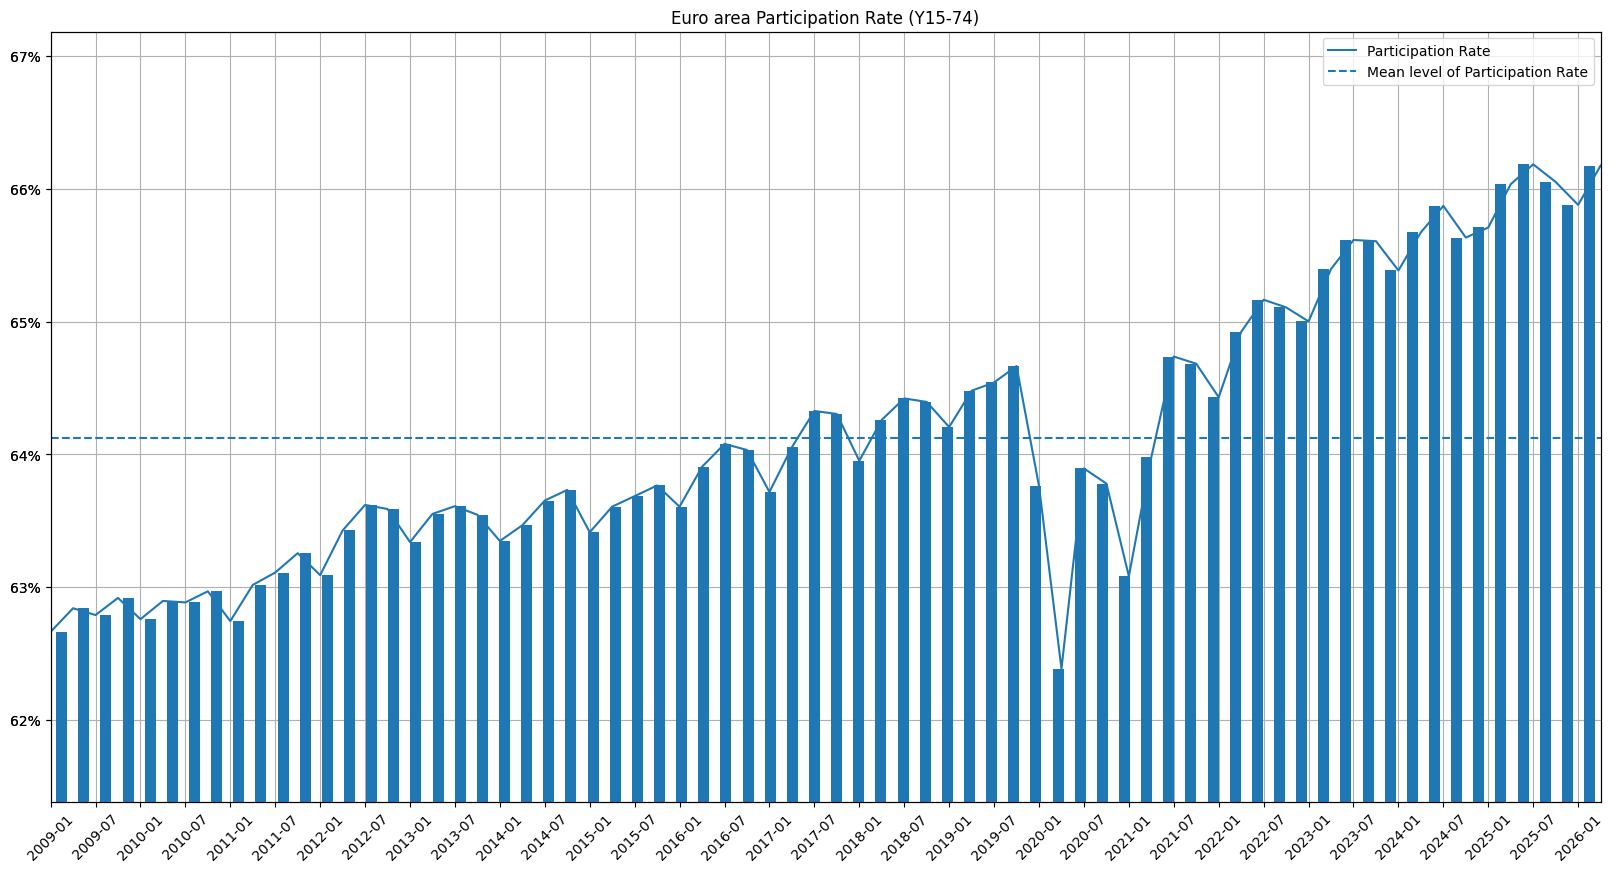

In [21]:
ax = ea_labour_mkt[PARTICIPATION_RATE].plot(figsize=(20,10), grid=True,
                                            title=EA_PFX + PARTICIPATION_RATE + f' ({AGE_GROUP})',
                                            xticks=ea_labour_mkt.index[::2], xlabel='', rot=45)
ax2 = ax.twiny()
min_pr, max_pr = ea_labour_mkt[PARTICIPATION_RATE].min() - .01, ea_labour_mkt[PARTICIPATION_RATE].max() + .01
with pd.plotting.plot_params.use('x_compat', True):
    ea_labour_mkt[PARTICIPATION_RATE].plot.bar(ax=ax2, xlabel='', ylim=(min_pr, max_pr), legend=False)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax2.xaxis.set_major_locator(mtick.NullLocator())
ax.axhline(y=ea_labour_mkt[PARTICIPATION_RATE].mean(), ls='--', c='#1f77b4', label=MEAN_PARTICIPATION_RATE)
ax.legend()
_ = ax.set_xticklabels(list(map('{:%Y-%m}'.format, ea_labour_mkt.index[::2])))

#### Unemployment rate

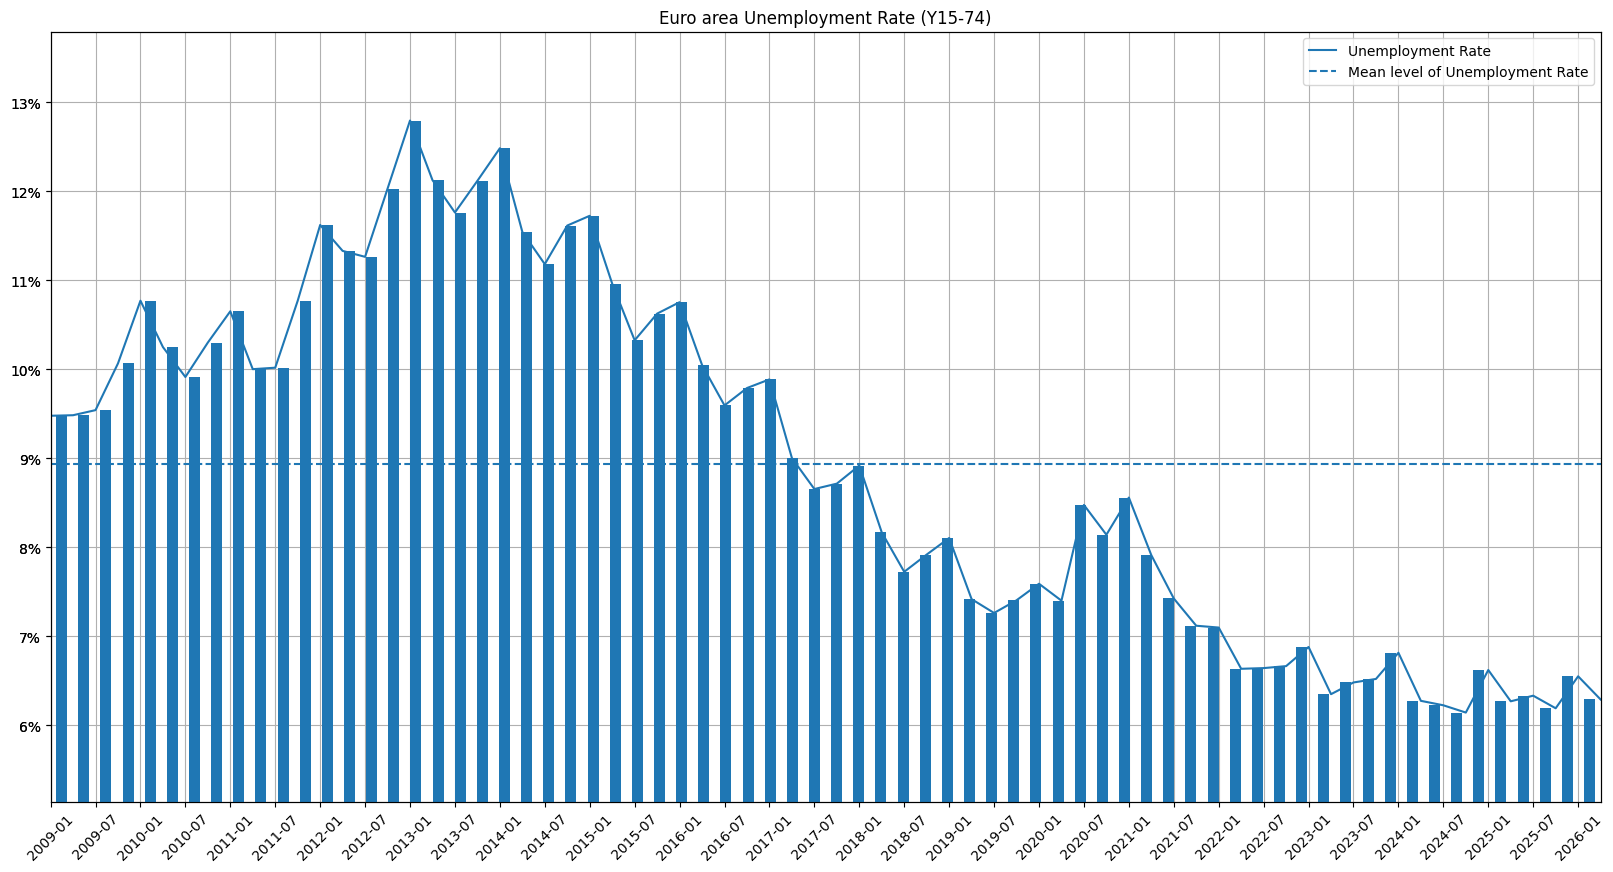

In [22]:
unempl_rate = ea_labour_mkt[UNEMPLOYMENT_RATE].dropna()
ax = unempl_rate.plot(figsize=(20,10), grid=True, xticks=unempl_rate.index[::2], xlabel='',
                      rot=45, title=EA_PFX + UNEMPLOYMENT_RATIO_GRAPH_TITLE + f' ({AGE_GROUP})')
ax2 = ax.twiny()
min_ur, max_ur = unempl_rate.min() - .01, unempl_rate.max() + .01
with pd.plotting.plot_params.use('x_compat', True):
    unempl_rate.plot.bar(ax=ax2, xlabel='', legend=False, ylim=(min_ur, max_ur))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax2.xaxis.set_major_locator(mtick.NullLocator())
ax.axhline(y=unempl_rate.mean(), ls='--', label=MEAN_UNEMPLOYMENT_RATE)
ax.legend()
_ = ax.set_xticklabels(list(map('{:%Y-%m}'.format, unempl_rate.index[::2])))

#### Job creation rate
I make use of the national concept labour-force numbers follow the Labour Force Survey (LFS) in calculating job creation.

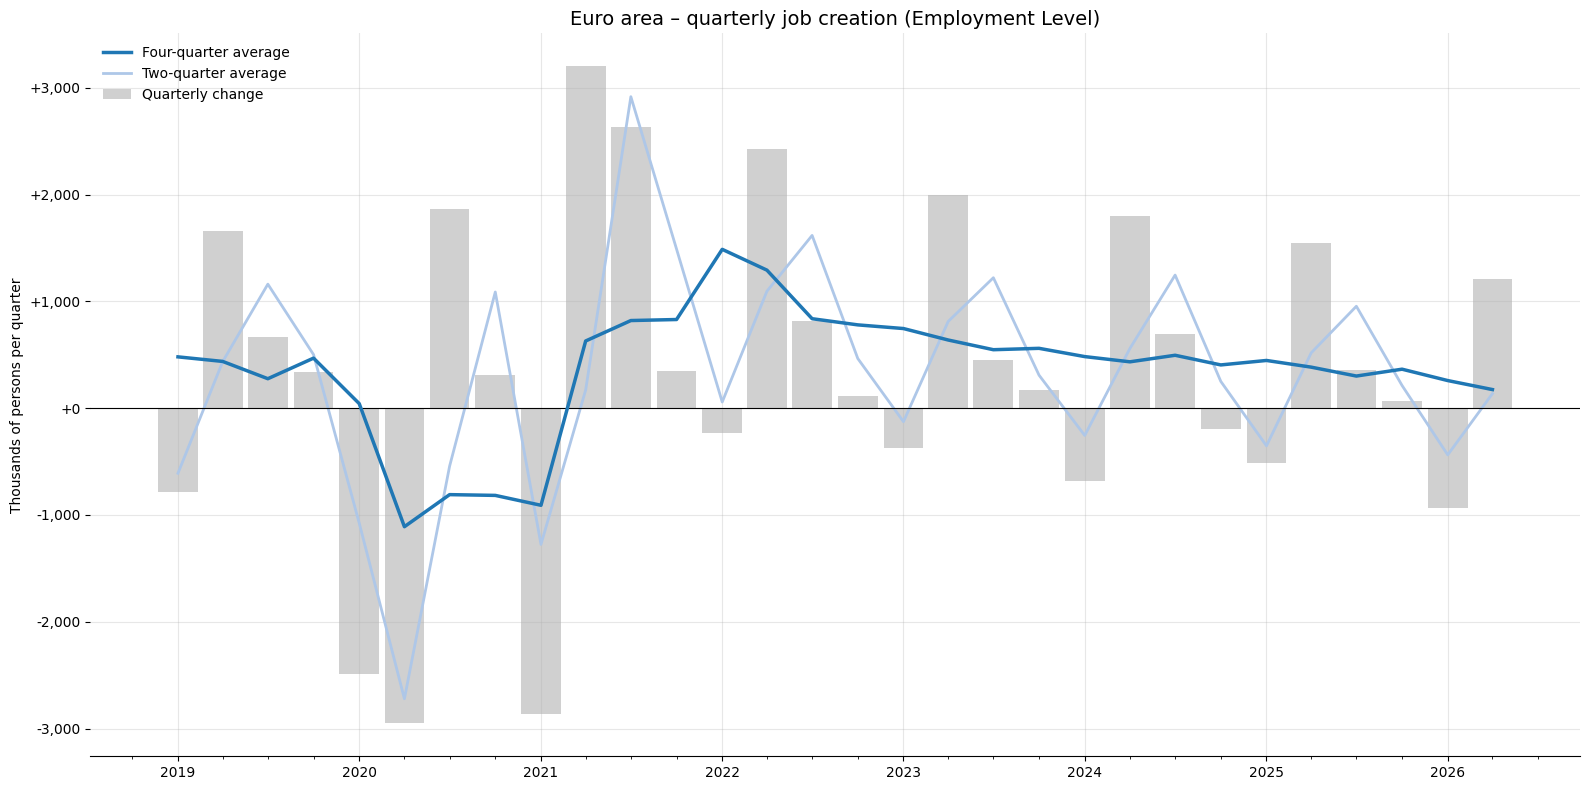

In [23]:
plot_smoothed_job_creation_quarterly(
    ea_labour_mkt[LABOUR_FORCE] - ea_labour_mkt[UNEMPLOYMENT_LEVEL],
    title='Euro area – quarterly job creation (Employment Level)')

#### Employment by Industry
While the headline employment and vacancy numbers tell us *how many* jobs the economy added or lost, they hide the underlying composition. Different industries can move in opposite directions in the same quarter.

The charts below decompose the latest quarterly change (and, when useful, the year-over-year change) into the main NACE A*10 industry groups from the national accounts.  
Positive bars show industries that added jobs; negative bars show industries that lost jobs.

*Note on the employment concept used here*  
Industry employment is taken from Eurostat national accounts (`namq_10_a10_e`, `EMP_DC` — domestic concept).  
It counts **persons engaged in resident production units**, including both:
- employees (people on a payroll), and  
- self-employed / independent contractors.

This is broader than the pure LFS employment level used earlier in the notebook for participation and unemployment rates (national concept, mainly resident persons in private households).  
It is also broader than the US CES non-farm payroll series (which largely exclude the self-employed).  

As a result, the industry totals and the job-creation figures derived from them are typically a little higher than the corresponding LFS-based employment changes.

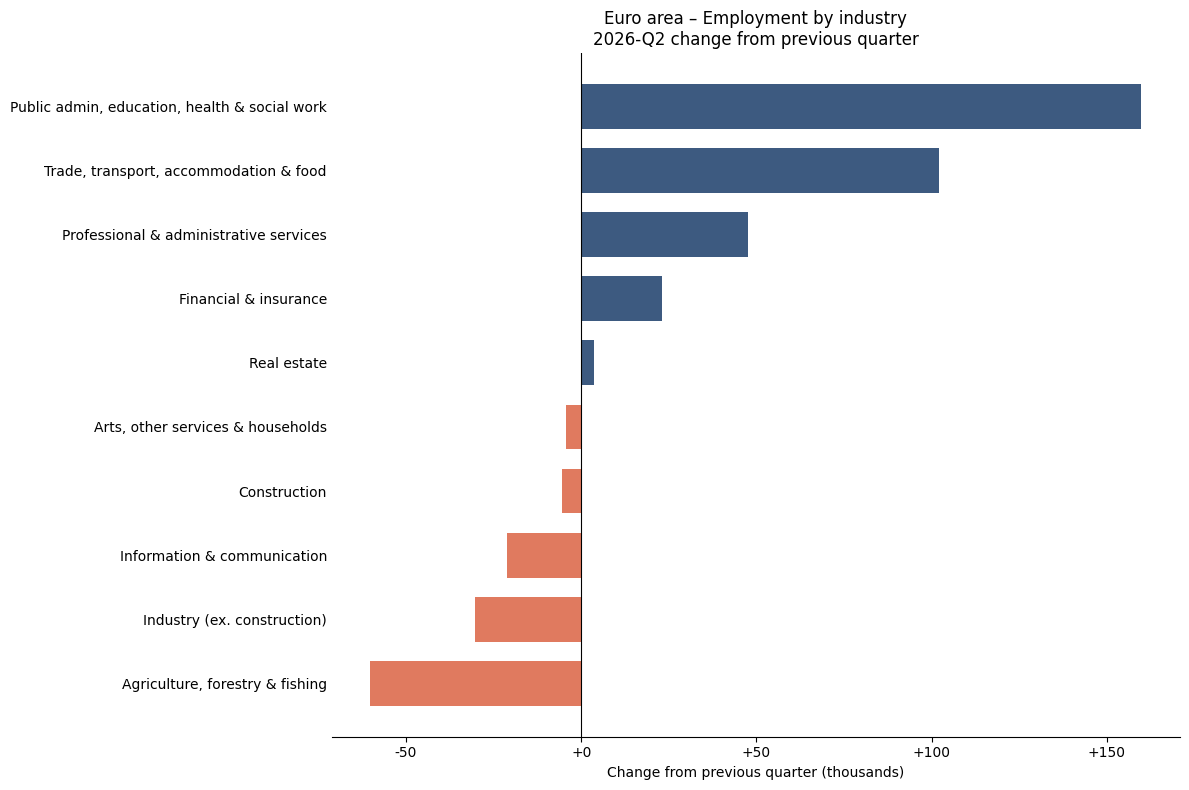

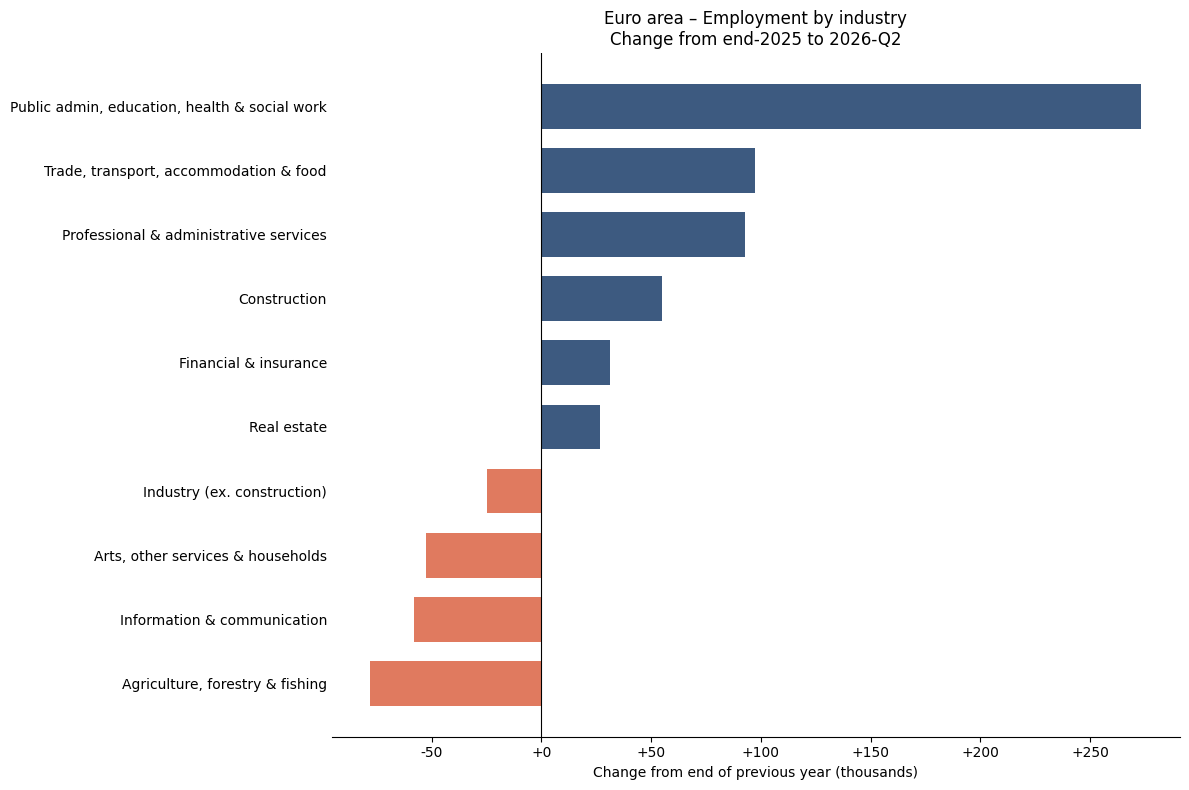

In [24]:
plot_employment_change_by_industry(ea_nl_jobs_by_industry, 'EA21', 'Euro area')

In [25]:
def industry_change_between(data, geo, start, end, exclude_manufacturing=True):
    geo_data = data[geo].drop(columns='Total')
    if exclude_manufacturing and 'Manufacturing' in geo_data.columns:
        geo_data = geo_data.drop(columns='Manufacturing')
    return (geo_data.loc[end] - geo_data.loc[start]).astype('int32').sort_values()

### The Netherlands
#### Participation Rate
[Het CBS](https://www.cbs.nl/en-gb/) distinguishes between netto and brutto participation rates. Netto participation rate is the ration of the number of people who work to the total number of people in the labour force. Brutto participation rate is the ration of the number of people who work or are looking for work to the total number of people in the labour force. Netto participation rate is therefore always smaller than the brutto participation rate. In this notebook I look exclusively at the brutto participation rate as it's more representative of the job market and is the most frequently used in literature.

As I've mentioned in the beginning of this notebook, I use not seasonally adjusted data.

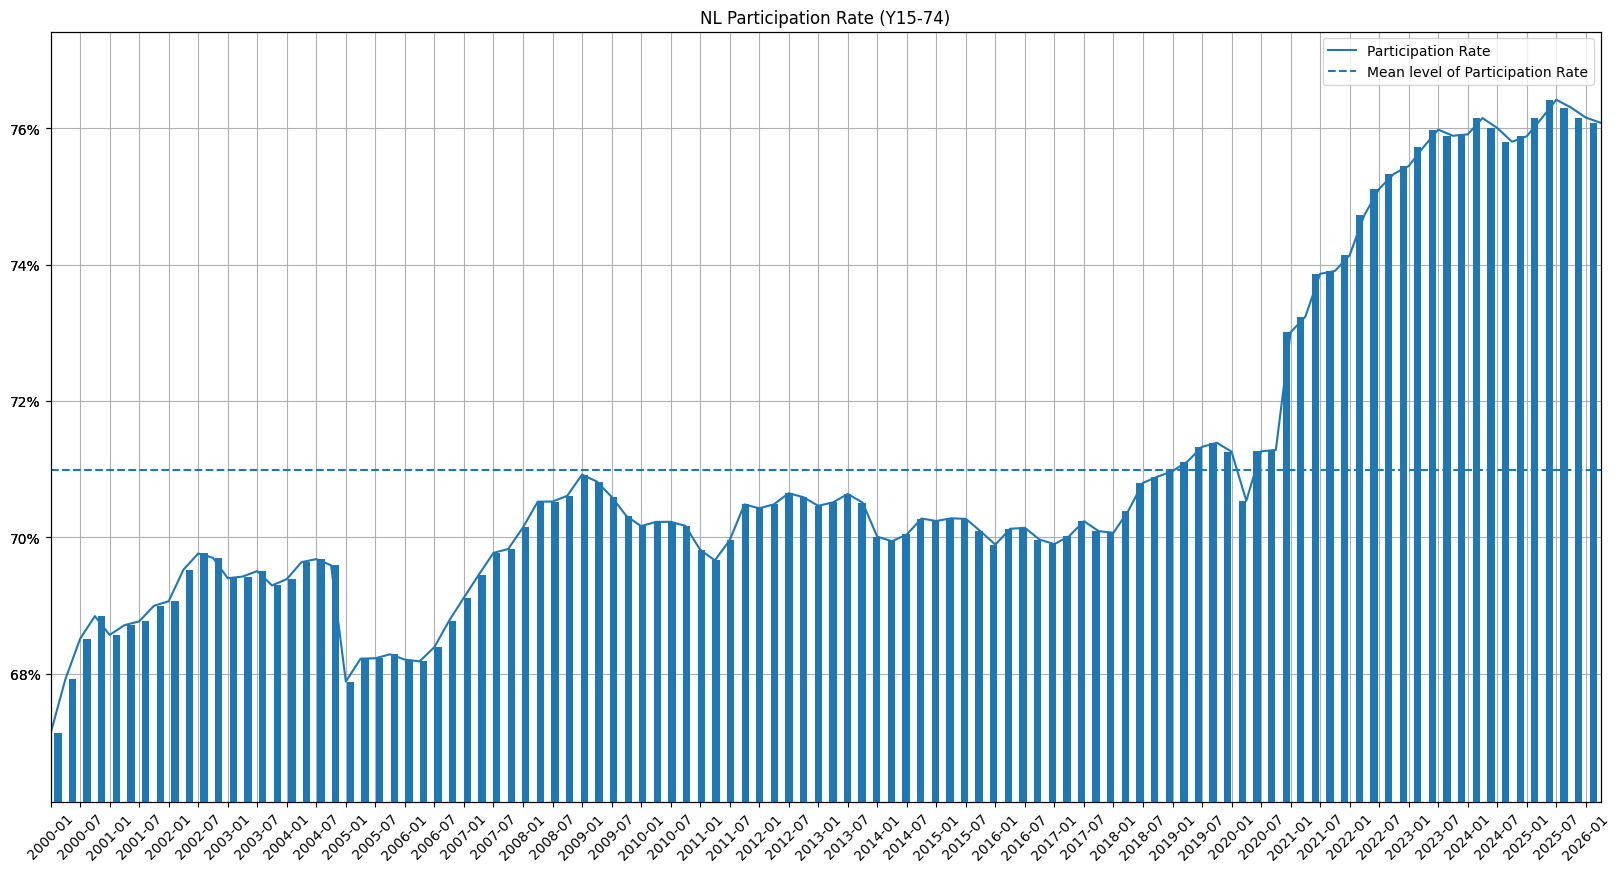

In [26]:
ax = nl_labour_mkt[PARTICIPATION_RATE].plot(figsize=(20,10), grid=True,
                                            title=NL_PFX + PARTICIPATION_RATE + f' ({AGE_GROUP})',
                                            xticks=nl_labour_mkt.index[::2], xlabel='', rot=45)
ax2 = ax.twiny()
min_pr, max_pr = nl_labour_mkt[PARTICIPATION_RATE].min() - .01, nl_labour_mkt[PARTICIPATION_RATE].max() + .01
with pd.plotting.plot_params.use('x_compat', True):
    nl_labour_mkt[PARTICIPATION_RATE].plot.bar(ax=ax2, xlabel='', ylim=(min_pr, max_pr), legend=False)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax2.xaxis.set_major_locator(mtick.NullLocator())
ax.axhline(y=nl_labour_mkt[PARTICIPATION_RATE].mean(), ls='--', c='#1f77b4', label=MEAN_PARTICIPATION_RATE)
ax.legend()
_ = ax.set_xticklabels(list(map('{:%Y-%m}'.format, nl_labour_mkt.index[::2])))

#### Unemployment rate

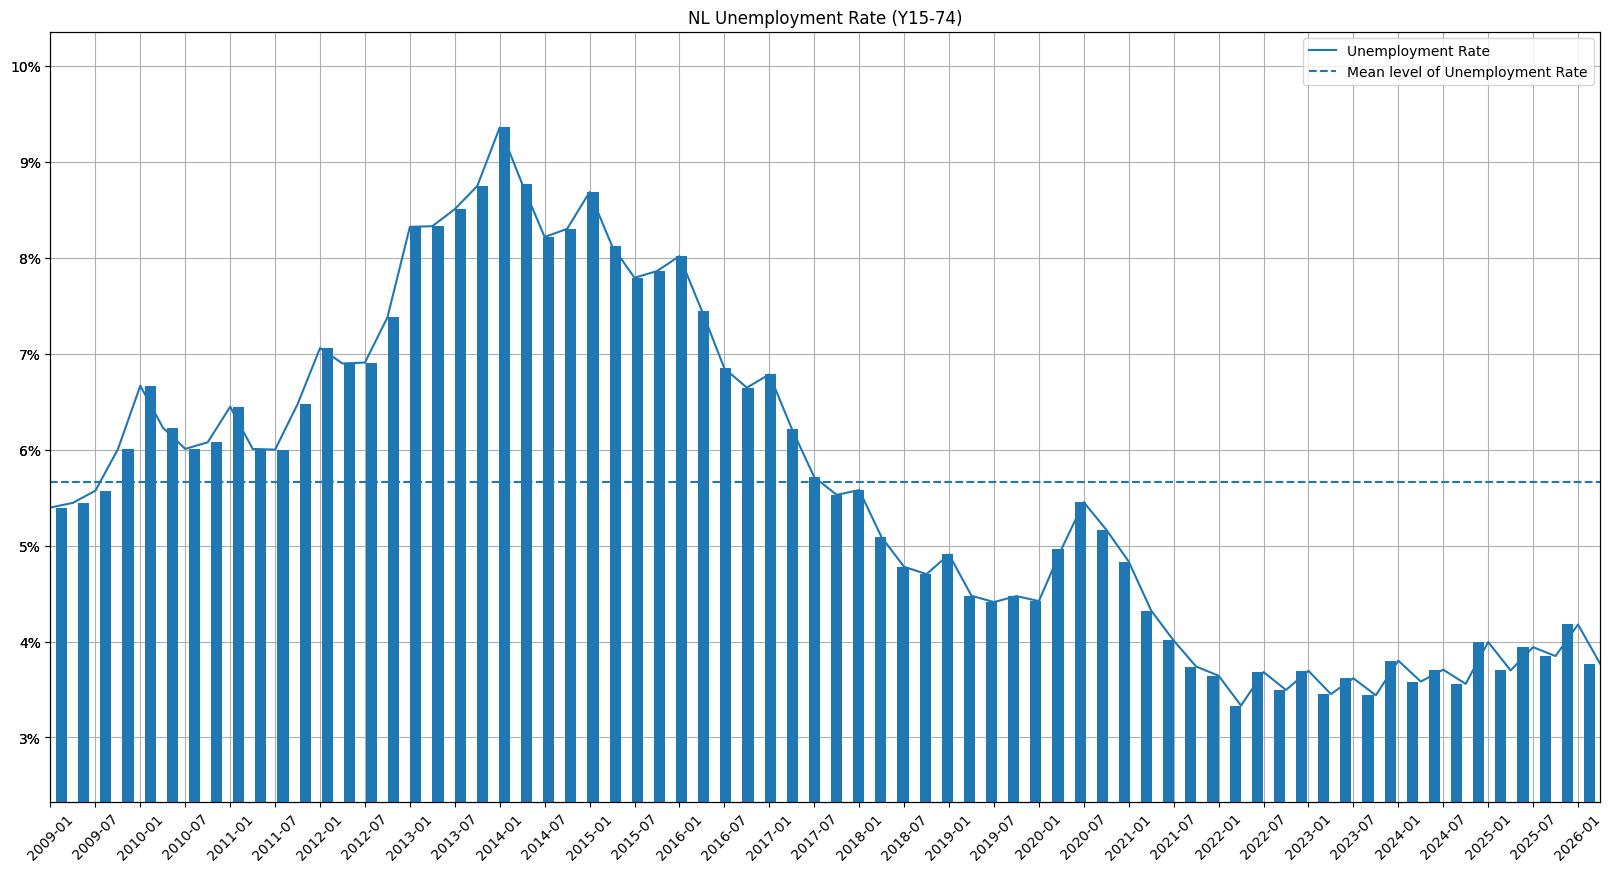

In [27]:
unempl_rate = nl_labour_mkt[UNEMPLOYMENT_RATE].dropna()
ax = unempl_rate.plot(figsize=(20,10), grid=True, xticks=unempl_rate.index[::2], xlabel='',
                      rot=45, title=NL_PFX + UNEMPLOYMENT_RATIO_GRAPH_TITLE + f' ({AGE_GROUP})')
ax2 = ax.twiny()
min_ur, max_ur = unempl_rate.min() - .01, unempl_rate.max() + .01
with pd.plotting.plot_params.use('x_compat', True):
    unempl_rate.plot.bar(ax=ax2, xlabel='', legend=False, ylim=(min_ur, max_ur))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax2.xaxis.set_major_locator(mtick.NullLocator())
ax.axhline(y=unempl_rate.mean(), ls='--', label=MEAN_UNEMPLOYMENT_RATE)
ax.legend()
_ = ax.set_xticklabels(list(map('{:%Y-%m}'.format, unempl_rate.index[::2])))

#### Job vacancy rate
_The Job Vacancy Rate_ (aka _The Unfilled Vacancies to Labor Force rate_) is by far the most well known measure of labour market tightness. It shows the ratio of unfilled vacancies to the labour force (i.e. the total pool of people who work or are looking for work). I like this measure more than _Job vacancies per unemployed_, which I describe further down in this notebook because in the present labour market an increasing number of vacancies are filled by job switchers rather than the unemployed.

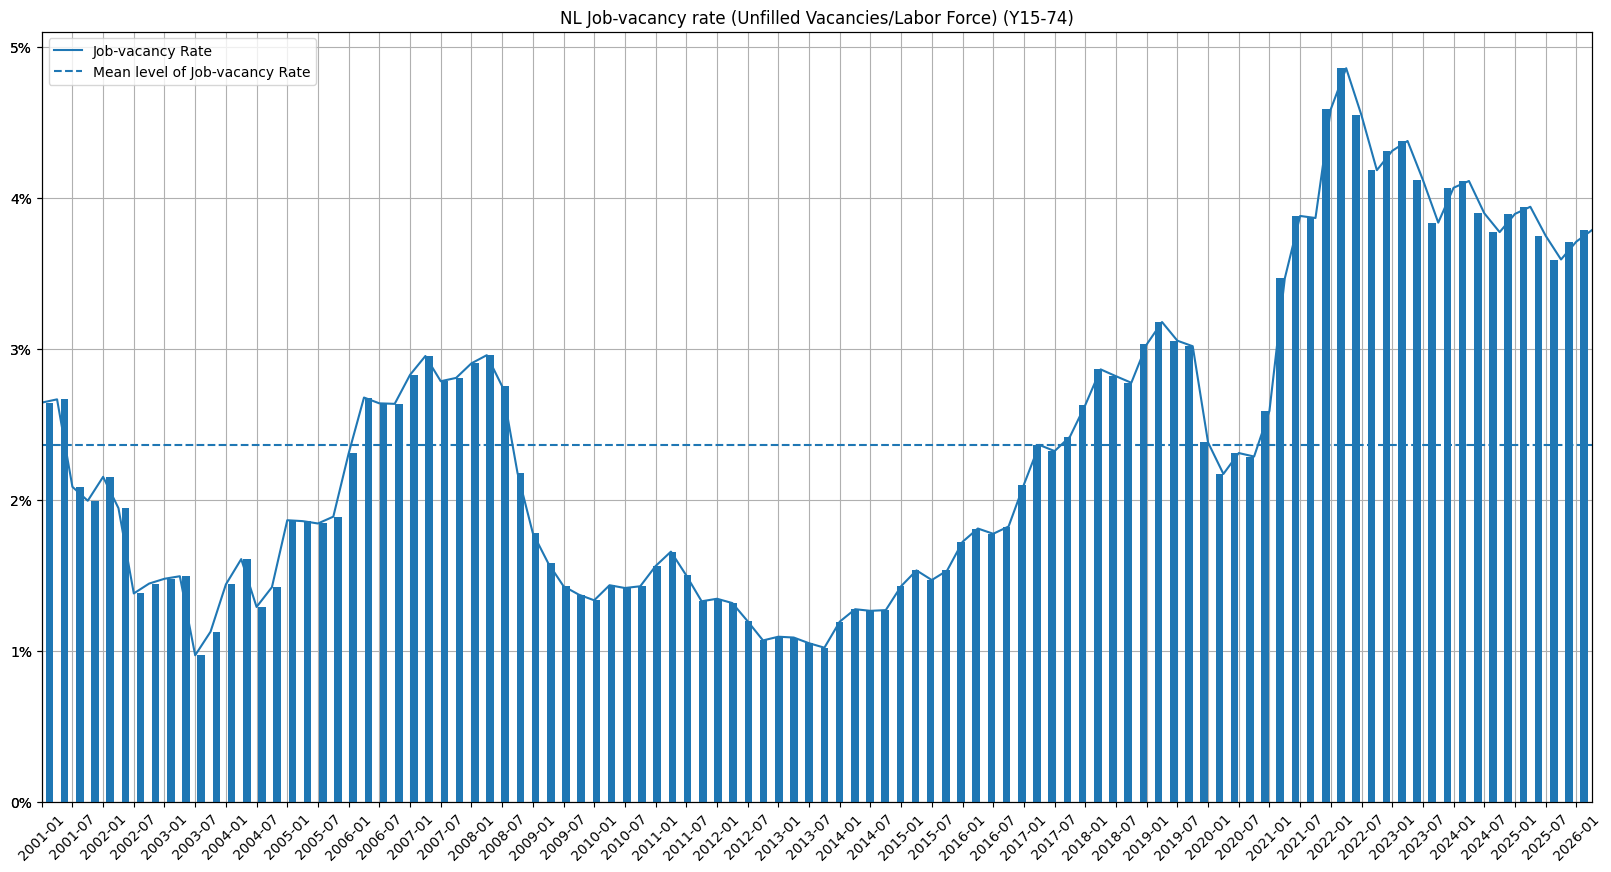

In [28]:
job_vac_rate = nl_labour_mkt[UNFILLED_VACANCIES_LABOR_FORCE_RATE].dropna()
ax = job_vac_rate.plot(figsize=(20,10), grid=True, xticks=job_vac_rate.index[::2], xlabel='', rot=45,
                       title=NL_PFX + JOB_VAC_RATE_GRAPH_TITLE + f' ({AGE_GROUP})')
ax2 = ax.twiny()
with pd.plotting.plot_params.use('x_compat', True):
    job_vac_rate.plot.bar(ax=ax2, xlabel='', legend=False)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax2.xaxis.set_major_locator(mtick.NullLocator())
ax.axhline(y=job_vac_rate.mean(), ls='--', label=MEAN_UNFILLED_VACANCIES_LABOR_FORCE_RATE)
ax.legend()
_ = ax.set_xticklabels(list(map('{:%Y-%m}'.format, job_vac_rate.index[::2])))

#### Job vacancies per unemployed person

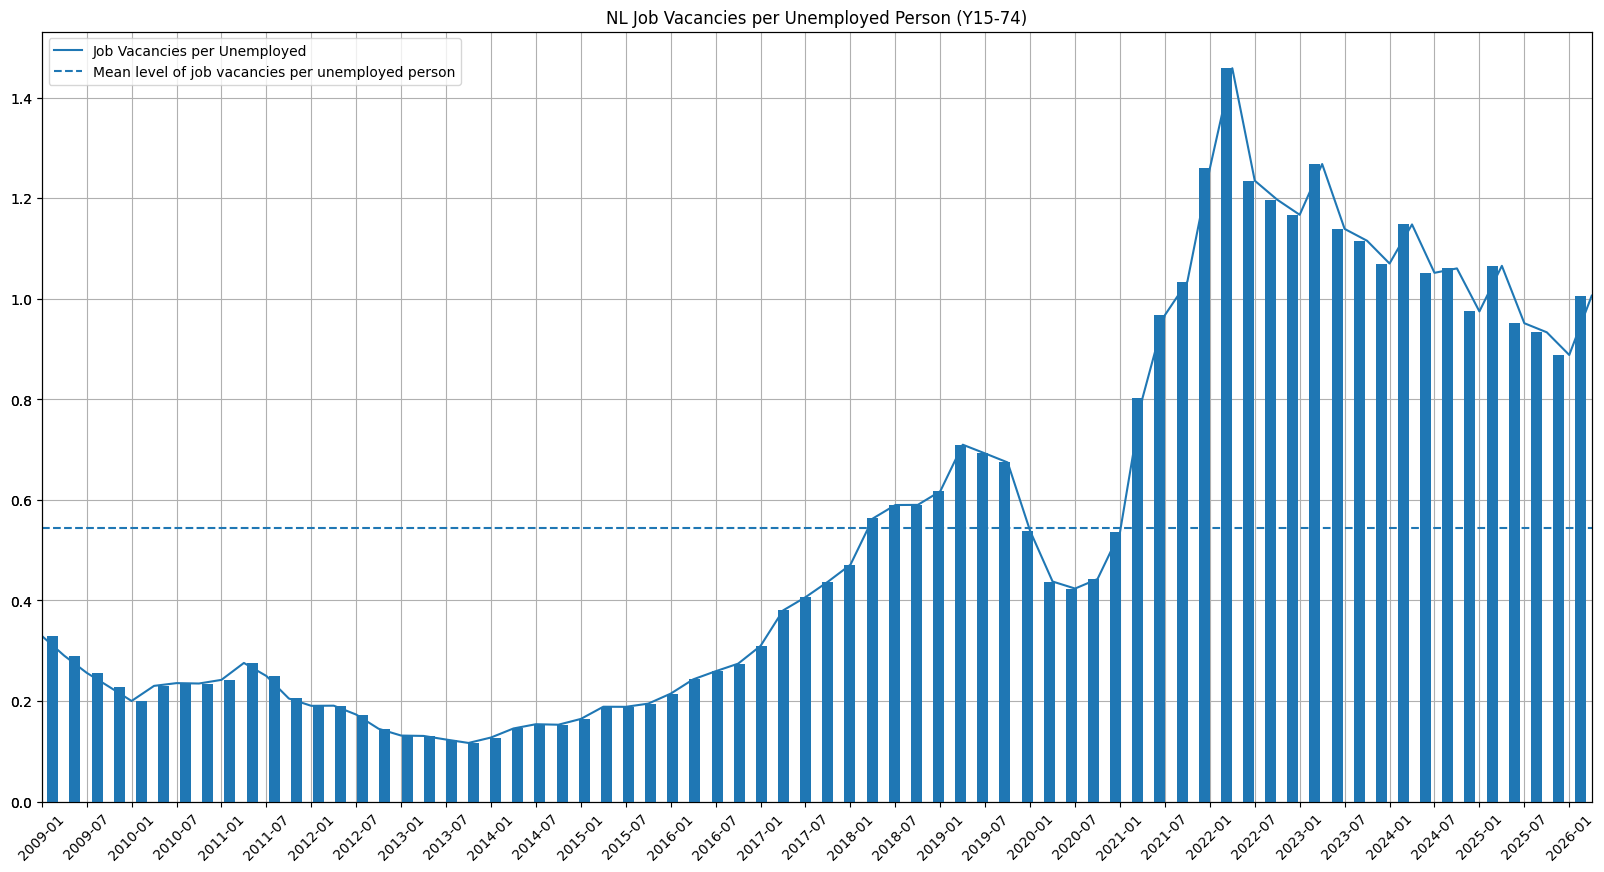

In [29]:
vac_per_unempl = nl_labour_mkt[JOB_VAC_PER_UNEMPLOYED].dropna()
ax = vac_per_unempl.plot(figsize=(20,10), grid=True, xticks=vac_per_unempl.index[::2], xlabel='', rot=45,
                         title=NL_PFX + JOB_VAC_PER_UNEMPLOYED_GRAPH_TITLE + ' ({:})'.format(AGE_GROUP))
ax2 = ax.twiny()
with pd.plotting.plot_params.use('x_compat', True):
    vac_per_unempl.plot.bar(ax=ax2, xlabel='', legend=False)
ax2.xaxis.set_major_locator(mtick.NullLocator())
ax.axhline(y=vac_per_unempl.mean(), ls='--', label=MEAN_VACANCIES_PER_UNEMPLOYED)
ax.legend()
_ = ax.set_xticklabels(list(map('{:%Y-%m}'.format, vac_per_unempl.index[::2])))

#### Job creation rate

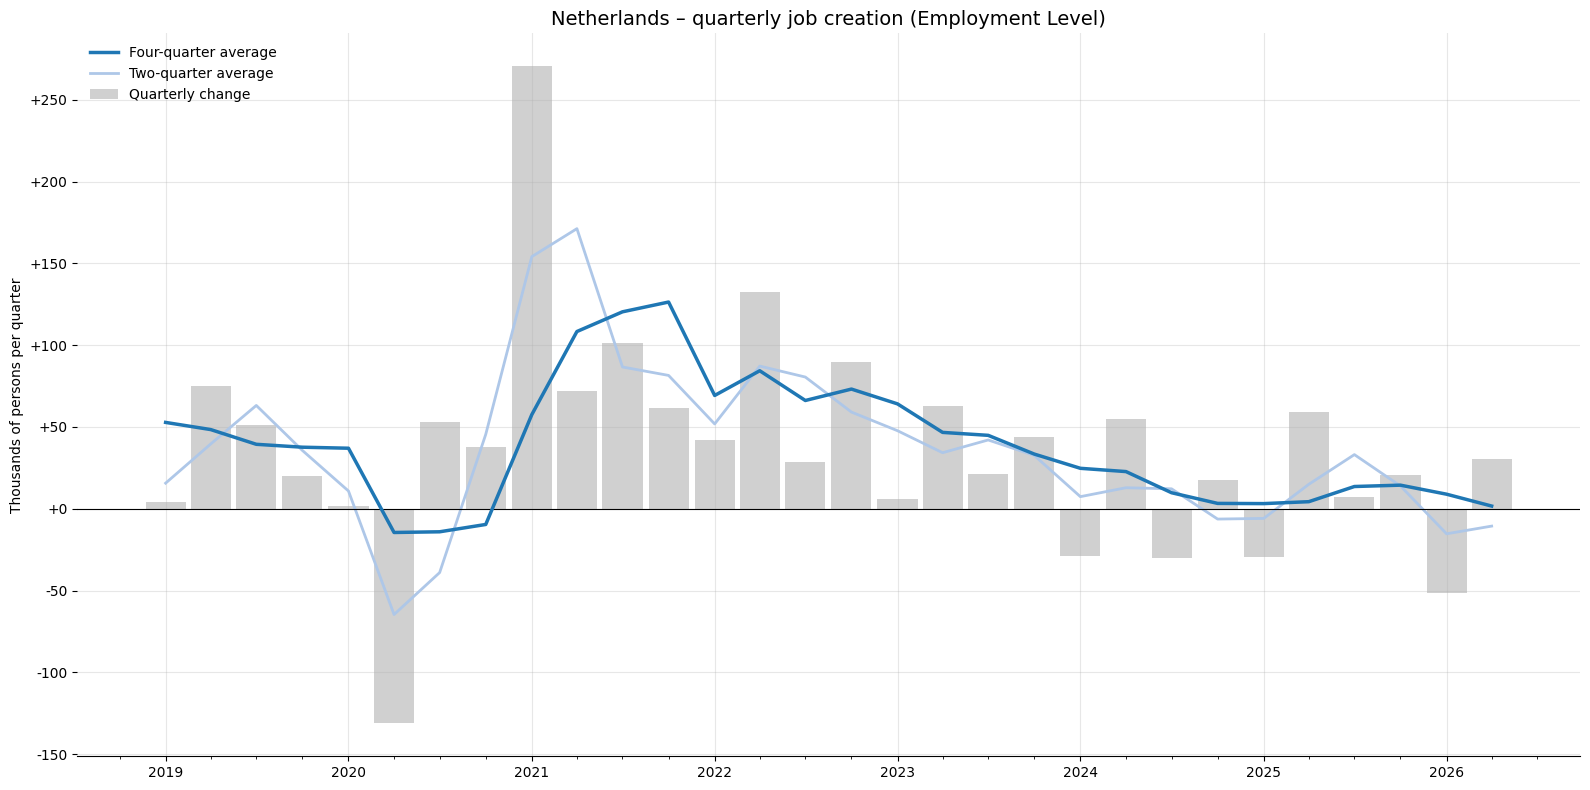

In [30]:
plot_smoothed_job_creation_quarterly(
    nl_labour_mkt[LABOUR_FORCE] - nl_labour_mkt[UNEMPLOYMENT_LEVEL],
    title='Netherlands – quarterly job creation (Employment Level)')

#### Employment by Industry
While the headline employment and vacancy numbers tell us *how many* jobs the economy added or lost, they hide the underlying composition. Different industries can move in opposite directions in the same quarter.

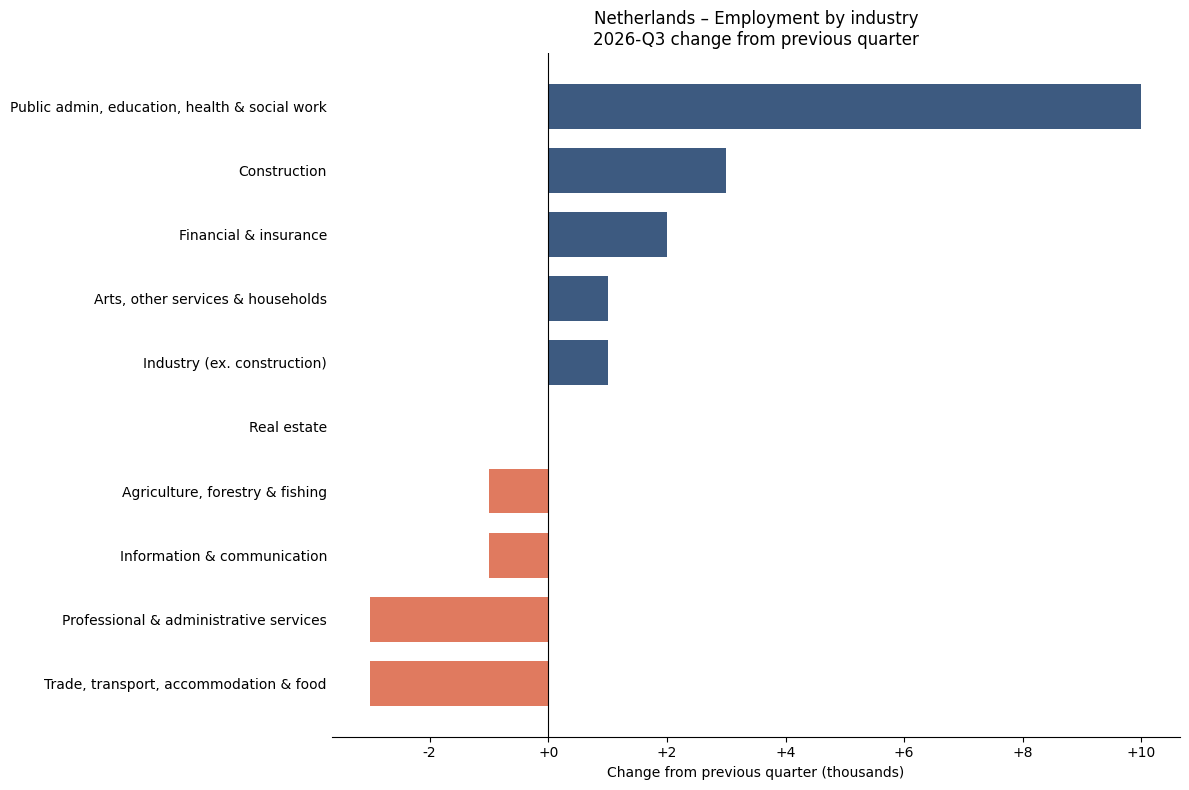

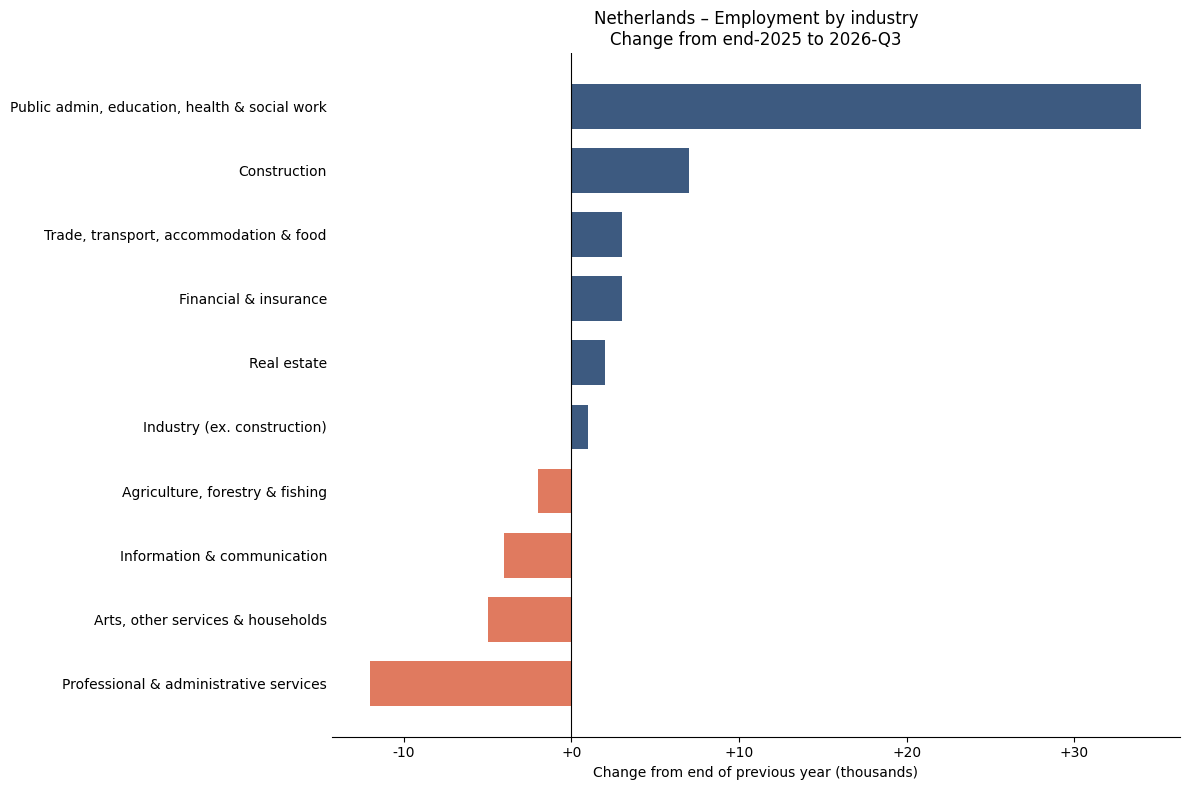

In [31]:
plot_employment_change_by_industry(ea_nl_jobs_by_industry, 'NL', 'Netherlands')

In [32]:
with pd.option_context('display.float_format', None):
    print(industry_change_between(ea_nl_jobs_by_industry, 'NL', '2024-04-01', '2026-07-01'))

industry
Trade, transport, accommodation & food           -26
Information & communication                       -8
Arts, other services & households                 -1
Industry (ex. construction)                        1
Financial & insurance                              2
Agriculture, forestry & fishing                    4
Real estate                                        6
Construction                                      12
Professional & administrative services            18
Public admin, education, health & social work    100
dtype: int32


### The Beveridge Curve
[The Beveridge Curve](https://en.wikipedia.org/wiki/Beveridge_curve) compares the unemployment rate to the job-vacancy rate (the number of job vacancies divided by the total labour force) and shows how this changes over time. I've looked at each of these rates individually earlier in this notebook, in this section I plot one against the other.

The Beveridge curve tends to show an inverse relationship — unfilled vacancies tend to increase as unemployment rate decreases. The logic being that when few are looking for a job, employers take longer to fill in their vacancies. Those years where the vacancy rate is higher for the same unemployment rate constitute less efficient a labor market where 1) skills mismatches between what employers are looking for and what job seekers have, or 2) vacancies being filled predominantly by job switchers rather than the jobless, or 3) lower willingness on the part of the unemployed to take a given job might be the reasons.

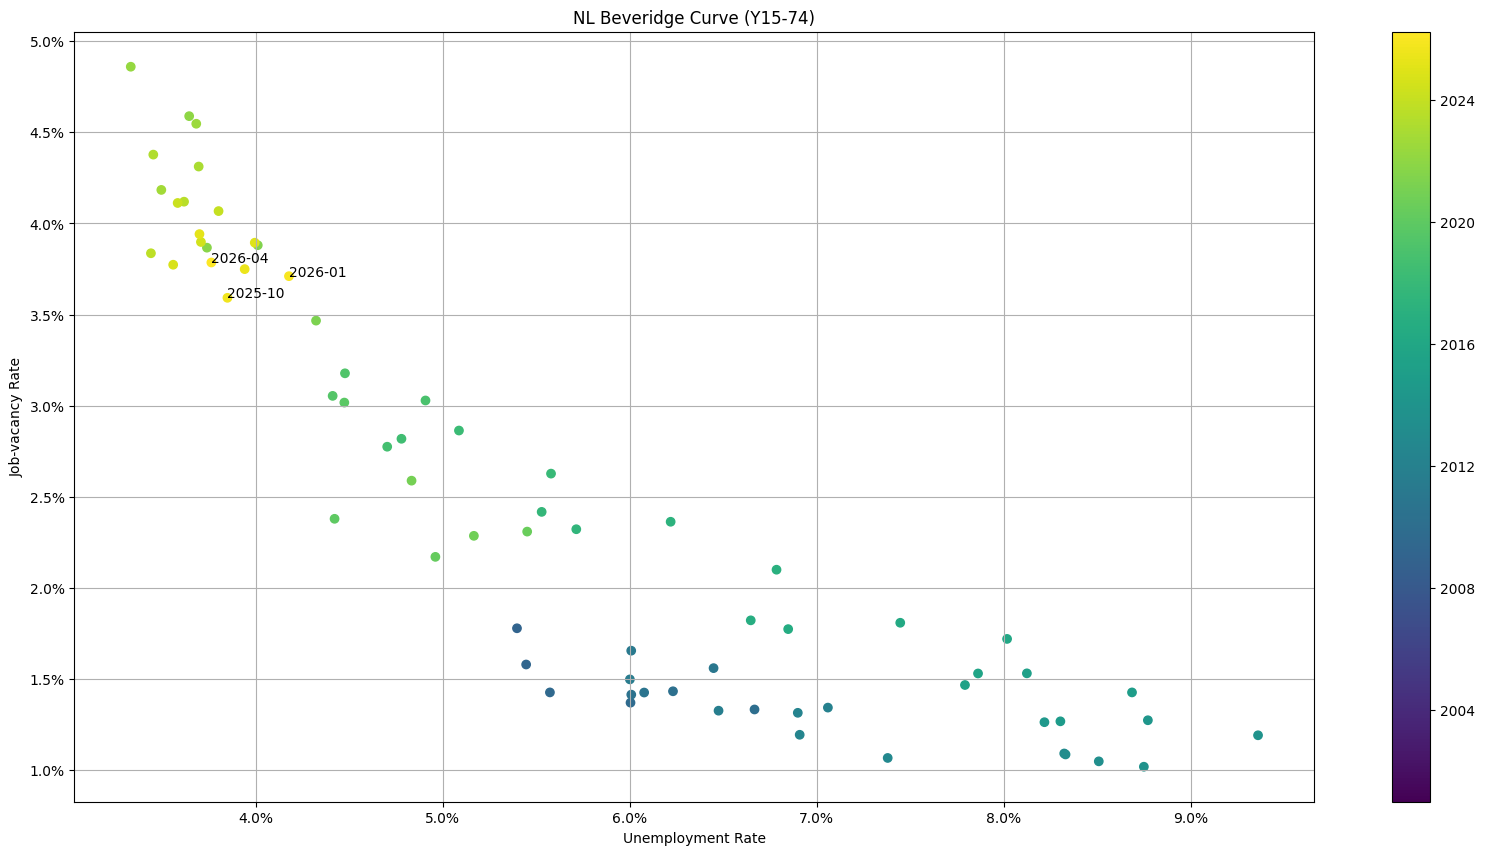

In [33]:
bvg_curve_df = nl_labour_mkt.loc[:, [UNEMPLOYMENT_RATE, UNFILLED_VACANCIES_LABOR_FORCE_RATE]]
fig, ax = plt.subplots(figsize=(20, 10))
sc = ax.scatter(x=bvg_curve_df.iloc[:,0], y=bvg_curve_df.iloc[:,1], c=mdates.date2num(bvg_curve_df.index))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_xlabel(bvg_curve_df.columns[0])
ax.set_ylabel(bvg_curve_df.columns[1])
ax.set_title(NL_PFX + 'Beveridge Curve ({:})'.format(AGE_GROUP))
# Add labels to the last three months for ease of understanding the current trend
for i in range(-1, -4, -1):
    plt.text(bvg_curve_df.iloc[i,0], bvg_curve_df.iloc[i,1], f'{bvg_curve_df.index[i]:%Y-%m}')
ax.grid(True)
loc = mdates.AutoDateLocator()
_ = fig.colorbar(sc, ticks=loc, format=mdates.AutoDateFormatter(loc))